PROBLEM: Estimate the diabetes disease-progression score using numerical measurements.
User: A data analyst studying relationships between patient measurements and a progression score.
Target y: disease progression score (a continuous numerical value).
Dataset source: Scikit-learn built-in Diabetes dataset; originally from the diabetes dataset described by Efron et al.

Dataset shape: (442, 11)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target: target


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



DATA TYPES
 bmi       float64
bp        float64
s5        float64
target    float64
dtype: object

SUMMARY STATISTICS
                 bmi            bp            s5      target
count  4.420000e+02  4.420000e+02  4.420000e+02  442.000000
mean  -2.245564e-16 -4.797570e-17  9.293722e-17  152.133484
std    4.761905e-02  4.761905e-02  4.761905e-02   77.093005
min   -9.027530e-02 -1.123988e-01 -1.260971e-01   25.000000
25%   -3.422907e-02 -3.665608e-02 -3.324559e-02   87.000000
50%   -7.283766e-03 -5.670422e-03 -1.947171e-03  140.500000
75%    3.124802e-02  3.564379e-02  3.243232e-02  211.500000
max    1.705552e-01  1.320436e-01  1.335973e-01  346.000000

Missing values:
 bmi       0
bp        0
s5        0
target    0
dtype: int64
Duplicate rows: 0
Shape after basic cleaning: (442, 4)
Decision: Only the selected numerical features are used. Missing values and duplicate rows are checked.


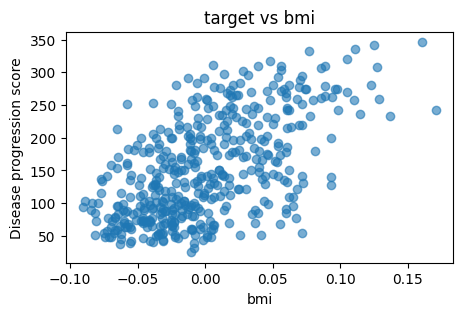

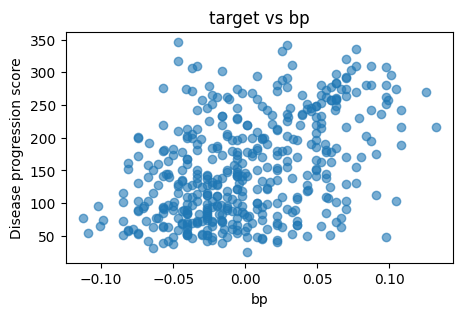

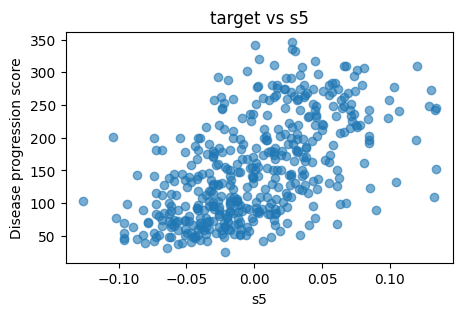

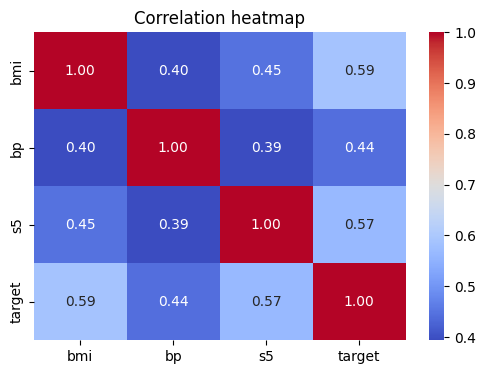

Observation: Correlation shows strength and direction of linear association; it does not prove causation.

MANUAL CALCULATION SAMPLE (6 rows)


,bmi,bp,target
0,0.061696,0.021872,151.0
1,-0.051474,-0.026328,75.0
2,0.044451,-0.005670,141.0
3,-0.011595,-0.036656,206.0
4,-0.036385,0.021872,135.0
5,-0.040696,-0.019442,97.0


Design matrix X:
 [[ 1.          0.06169621  0.02187239]
 [ 1.         -0.05147406 -0.02632753]
 [ 1.          0.04445121 -0.00567042]
 [ 1.         -0.01159501 -0.03665608]
 [ 1.         -0.03638469  0.02187239]
 [ 1.         -0.04069594 -0.01944183]]
Target vector y:
 [151.  75. 141. 206. 135.  97.]
X transpose X:
 [[ 6.00000000e+00 -3.40022886e-02 -4.43510867e-02]
 [-3.40022886e-02  1.15463610e-02  2.87298204e-03]
 [-4.43510867e-02  2.87298204e-03  3.40374781e-03]]
X transpose y:
 [ 8.05000000e+02  4.75181008e-01 -5.95560174e+00]
Solved coefficients [b0, b1, b2]: [ 133.80423154  552.85036144 -472.88104656]
Manual fitted equation: y = 133.8042 + (552.8504 * bmi) + (-472.8810 * bp)
Prediction for first sample: 157.57
Actual value: 151.0
Residual (actual - predicted): -6.57
Library intercept: 133.8042315418851
Library coefficients: [ 552.85036144 -472.88104656]
Manual and library calculations should be approximately equal.

Train rows: 353 | Test rows: 89
Single model intercept: 152.00

,Feature,Coefficient
0,bmi,650.631383
1,bp,283.898900
2,s5,491.982712


Multiple regression equation:
target = 151.674 + (650.631*bmi) + (283.899*bp) + (491.983*s5)

TEST SET MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2,Adjusted R2
0,Single-feature (bmi),52.260,4061.826,63.732,0.233,0.225
1,"Multiple-feature (bmi, bp, s5)",44.288,2891.037,53.768,0.454,0.435


MAE is average absolute error; RMSE is in target units. R2 compares performance with predicting the mean. Adjusted R2 penalises unnecessary features.

ACTUAL VS PREDICTED (sample)


,Actual,Predicted
0,219.0,159.05
1,70.0,170.82
2,202.0,187.04
3,230.0,256.54
4,111.0,135.36
5,84.0,117.71
6,242.0,283.45
7,272.0,224.01
8,94.0,88.50
9,96.0,141.01


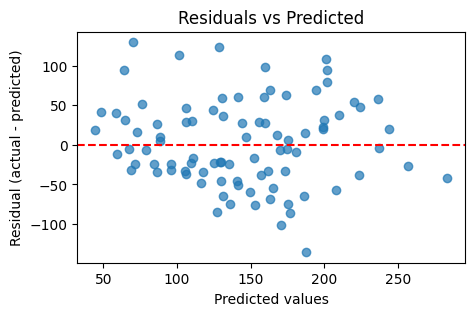

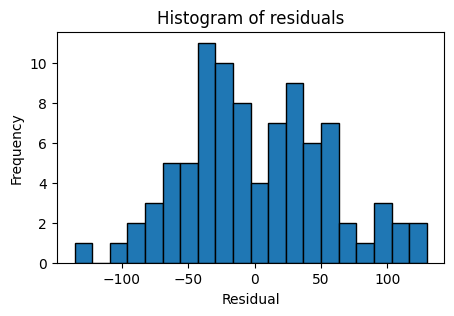

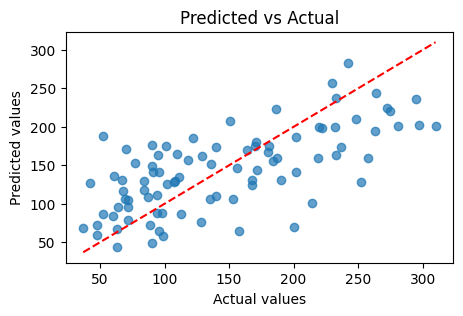


VIF CHECK (higher values can indicate multicollinearity)


,Feature,VIF
0,bmi,1.345
1,bp,1.274
2,s5,1.342


Linear regression assumptions: linearity, independent errors, constant error variance, approximately normal errors and no severe multicollinearity. Plots and VIF help diagnose them.

NEW EXAMPLE:


,bmi,bp,s5
0,-0.005128,-0.00567,-0.000612


Predicted disease progression score: 146.43

CONCLUSION:
The model estimates a continuous disease-progression score from BMI, blood pressure and s5. Compare the single and multiple model test metrics to decide whether extra features help.
Limitations: This is a teaching dataset and the model is not a medical diagnostic tool. Correlation does not prove causation; other factors may affect the target.
Possible improvement: test other features or models and validate on additional data.


In [1]:
# ACTIVITY 1: MULTIPLE LINEAR REGRESSION
# Dataset: Diabetes dataset built into Scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Problem statement and dataset
print("PROBLEM: Estimate the diabetes disease-progression score using numerical measurements.")
print("User: A data analyst studying relationships between patient measurements and a progression score.")
print("Target y: disease progression score (a continuous numerical value).")
print("Dataset source: Scikit-learn built-in Diabetes dataset; originally from the diabetes dataset described by Efron et al.")
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()
print("\nDataset shape:", df.shape)
print("Features:", list(diabetes.feature_names))
print("Target: target")
display(df.head())

# We select three numerical features for a manageable multiple regression model.
features = ['bmi', 'bp', 's5']
target = 'target'
data = df[features + [target]].copy()

# 2. Inspect and clean
print("\nDATA TYPES\n", data.dtypes)
print("\nSUMMARY STATISTICS\n", data.describe())
print("\nMissing values:\n", data.isnull().sum())
print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates().dropna()
print("Shape after basic cleaning:", data.shape)
print("Decision: Only the selected numerical features are used. Missing values and duplicate rows are checked.")

# 3. Visualise relationships
for feature in features:
    plt.figure(figsize=(5,3))
    plt.scatter(data[feature], data[target], alpha=0.6)
    plt.title(f'{target} vs {feature}')
    plt.xlabel(feature)
    plt.ylabel('Disease progression score')
    plt.show()

plt.figure(figsize=(6,4))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation heatmap')
plt.show()
print("Observation: Correlation shows strength and direction of linear association; it does not prove causation.")

# 4. Manual calculation using 6 observations and two features
small = data[['bmi', 'bp', 'target']].head(6).copy()
X_small = np.column_stack([np.ones(len(small)), small[['bmi','bp']].values])
y_small = small['target'].values
print("\nMANUAL CALCULATION SAMPLE (6 rows)")
display(small)
XtX = X_small.T @ X_small
Xty = X_small.T @ y_small
print("Design matrix X:\n", X_small)
print("Target vector y:\n", y_small)
print("X transpose X:\n", XtX)
print("X transpose y:\n", Xty)
manual_b = np.linalg.pinv(XtX) @ Xty
print("Solved coefficients [b0, b1, b2]:", manual_b)
print(f"Manual fitted equation: y = {manual_b[0]:.4f} + ({manual_b[1]:.4f} * bmi) + ({manual_b[2]:.4f} * bp)")
manual_pred = float(X_small[0] @ manual_b)
manual_resid = float(y_small[0] - manual_pred)
print("Prediction for first sample:", round(manual_pred, 3))
print("Actual value:", round(float(y_small[0]), 3))
print("Residual (actual - predicted):", round(manual_resid, 3))

# Verify manual calculation with library on same small sample
verify = LinearRegression().fit(small[['bmi','bp']], y_small)
print("Library intercept:", verify.intercept_)
print("Library coefficients:", verify.coef_)
print("Manual and library calculations should be approximately equal.")

# 5. Train/test split; compare single-feature and multiple-feature models
X = data[features]
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
single = LinearRegression().fit(X_train[['bmi']], y_train)
multi = LinearRegression().fit(X_train, y_train)
pred_single = single.predict(X_test[['bmi']])
pred_multi = multi.predict(X_test)

def adjusted_r2(r2, n, p):
    return 1 - (1-r2)*(n-1)/(n-p-1)

def metrics_row(name, actual, predicted, p):
    r2 = r2_score(actual, predicted)
    return {
        'Model': name,
        'MAE': mean_absolute_error(actual, predicted),
        'MSE': mean_squared_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'R2': r2,
        'Adjusted R2': adjusted_r2(r2, len(actual), p)
    }

comparison = pd.DataFrame([
    metrics_row('Single-feature (bmi)', y_test, pred_single, 1),
    metrics_row('Multiple-feature (bmi, bp, s5)', y_test, pred_multi, len(features))
])
print("\nTrain rows:", len(X_train), "| Test rows:", len(X_test))
print("Single model intercept:", single.intercept_, "| coefficient:", single.coef_[0])
print("Multiple model intercept:", multi.intercept_)
print("Multiple model coefficients:")
display(pd.DataFrame({'Feature':features, 'Coefficient':multi.coef_}))
print("Multiple regression equation:")
print(f"target = {multi.intercept_:.3f} + ({multi.coef_[0]:.3f}*bmi) + ({multi.coef_[1]:.3f}*bp) + ({multi.coef_[2]:.3f}*s5)")
print("\nTEST SET MODEL COMPARISON")
display(comparison.round(3))
print("MAE is average absolute error; RMSE is in target units. R2 compares performance with predicting the mean. Adjusted R2 penalises unnecessary features.")

# Actual vs predicted sample
pred_table = pd.DataFrame({'Actual': y_test.values, 'Predicted': pred_multi})
print("\nACTUAL VS PREDICTED (sample)")
display(pred_table.head(10).round(2))

# 6. Residual analysis
residuals = y_test.values - pred_multi
plt.figure(figsize=(5,3))
plt.scatter(pred_multi, residuals, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs Predicted')
plt.xlabel('Predicted values')
plt.ylabel('Residual (actual - predicted)')
plt.show()

plt.figure(figsize=(5,3))
plt.hist(residuals, bins=20, edgecolor='black')
plt.title('Histogram of residuals')
plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(5,3))
plt.scatter(y_test, pred_multi, alpha=0.7)
low, high = min(y_test.min(), pred_multi.min()), max(y_test.max(), pred_multi.max())
plt.plot([low, high], [low, high], 'r--')
plt.title('Predicted vs Actual')
plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.show()

# 7. Multicollinearity using correlation and VIF
vif_data = pd.DataFrame()
vif_data['Feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nVIF CHECK (higher values can indicate multicollinearity)")
display(vif_data.round(3))
print("Linear regression assumptions: linearity, independent errors, constant error variance, approximately normal errors and no severe multicollinearity. Plots and VIF help diagnose them.")

# 8. New example prediction using typical feature values within dataset ranges
new_record = pd.DataFrame([X_train.median()], columns=features)
new_prediction = multi.predict(new_record)[0]
print("\nNEW EXAMPLE:")
display(new_record)
print("Predicted disease progression score:", round(float(new_prediction), 2))
print("\nCONCLUSION:")
print("The model estimates a continuous disease-progression score from BMI, blood pressure and s5. Compare the single and multiple model test metrics to decide whether extra features help.")
print("Limitations: This is a teaching dataset and the model is not a medical diagnostic tool. Correlation does not prove causation; other factors may affect the target.")
print("Possible improvement: test other features or models and validate on additional data.")
